In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
info = pd.read_excel(r'C:\Users\micha\Desktop\modeling_prac\retail_loans.xlsx')
info.to_csv(r'C:\Users\micha\Desktop\modeling_prac\retail_loans.csv', index=False)
print(info.columns.tolist())

['Unnamed: 0', 'id', 'vintage_year', 'monthly_installment', 'loan_balance', 'bureau_score', 'num_bankrupt_iva', 'time_since_bankrupt', 'num_ccj', 'time_since_ccj', 'ccj_amount', 'num_bankrupt', 'num_iva', 'min_months_since_bankrupt', 'pl_flag', 'region', 'ltv', 'arrears_months', 'origination_date', 'maturity_date', 'repayment_type', 'arrears_status', 'arrears_segment', 'mob', 'remaining_mat', 'loan_term', 'live_status', 'repaid_status', 'month', 'arrears_event', 'bankrupt_event', 'term_expiry_event', 'worst_arrears_status', 'max_arrears_12m', 'recent_arrears_date', 'months_since_2mia', 'avg_mia_6m', 'max_arrears_bal_6m', 'max_mia_6m', 'avg_bal_6m', 'avg_bureau_score_6m', 'cc_util', 'annual_income', 'emp_length', 'months_since_recent_cc_delinq']


In [4]:
condition = (info['arrears_status'] == 1) | (info['term_expiry_event'] == 1) | (info['bankrupt_event'] == 1)
# Default condition to be searched in the data

info['Default'] = np.where(condition, 1, 0)
# column added to data that lists the default status for each loan portfolio

In [5]:
print(info.columns)

Index(['Unnamed: 0', 'id', 'vintage_year', 'monthly_installment',
       'loan_balance', 'bureau_score', 'num_bankrupt_iva',
       'time_since_bankrupt', 'num_ccj', 'time_since_ccj', 'ccj_amount',
       'num_bankrupt', 'num_iva', 'min_months_since_bankrupt', 'pl_flag',
       'region', 'ltv', 'arrears_months', 'origination_date', 'maturity_date',
       'repayment_type', 'arrears_status', 'arrears_segment', 'mob',
       'remaining_mat', 'loan_term', 'live_status', 'repaid_status', 'month',
       'arrears_event', 'bankrupt_event', 'term_expiry_event',
       'worst_arrears_status', 'max_arrears_12m', 'recent_arrears_date',
       'months_since_2mia', 'avg_mia_6m', 'max_arrears_bal_6m', 'max_mia_6m',
       'avg_bal_6m', 'avg_bureau_score_6m', 'cc_util', 'annual_income',
       'emp_length', 'months_since_recent_cc_delinq', 'Default'],
      dtype='object')


In [6]:
from sklearn.model_selection import train_test_split

# remove default indicator column from data
X = info.drop('Default', axis=1)

# assign default data to y variable
y = info['Default']

# split data into test and train groups
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [29]:
from optbinning import BinningProcess

# features to be plotted in Information value table from above assignment of X variable
features = X_train

# binning of features requires 'features' dataframe from above line to be converted to a list
bin_process = BinningProcess(variable_names = features.columns.to_list())

features_aligned, y_aligned = features.align(y_train, join="inner", axis=0)

a = features_aligned.to_numpy()
b = y_aligned.to_numpy()

# features and 'default column' need to be converted to arrays before they can be fit in bin_process
# = features.to_numpy()
#b = y.to_numpy()

bin_process.fit(a, b)

# summary of iv values for each feature - provided as a string of iv values with the features
iv_summary = bin_process.summary()
print(iv_summary[['name','iv']])


C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' wa

                             name        iv
0                      Unnamed: 0       0.0
1                              id       0.0
2                    vintage_year  0.016738
3             monthly_installment  4.246837
4                    loan_balance       0.0
5                    bureau_score  1.763697
6                num_bankrupt_iva  0.000466
7             time_since_bankrupt  0.000466
8                         num_ccj  0.361614
9                  time_since_ccj  0.374904
10                     ccj_amount  0.000466
11                   num_bankrupt  0.000466
12                        num_iva  0.000466
13      min_months_since_bankrupt  0.000466
14                        pl_flag  0.026777
15                         region  0.023847
16                            ltv  3.307521
17                 arrears_months       0.0
18               origination_date  1.086405
19                  maturity_date  0.438535
20                 repayment_type  0.000281
21                 arrears_statu

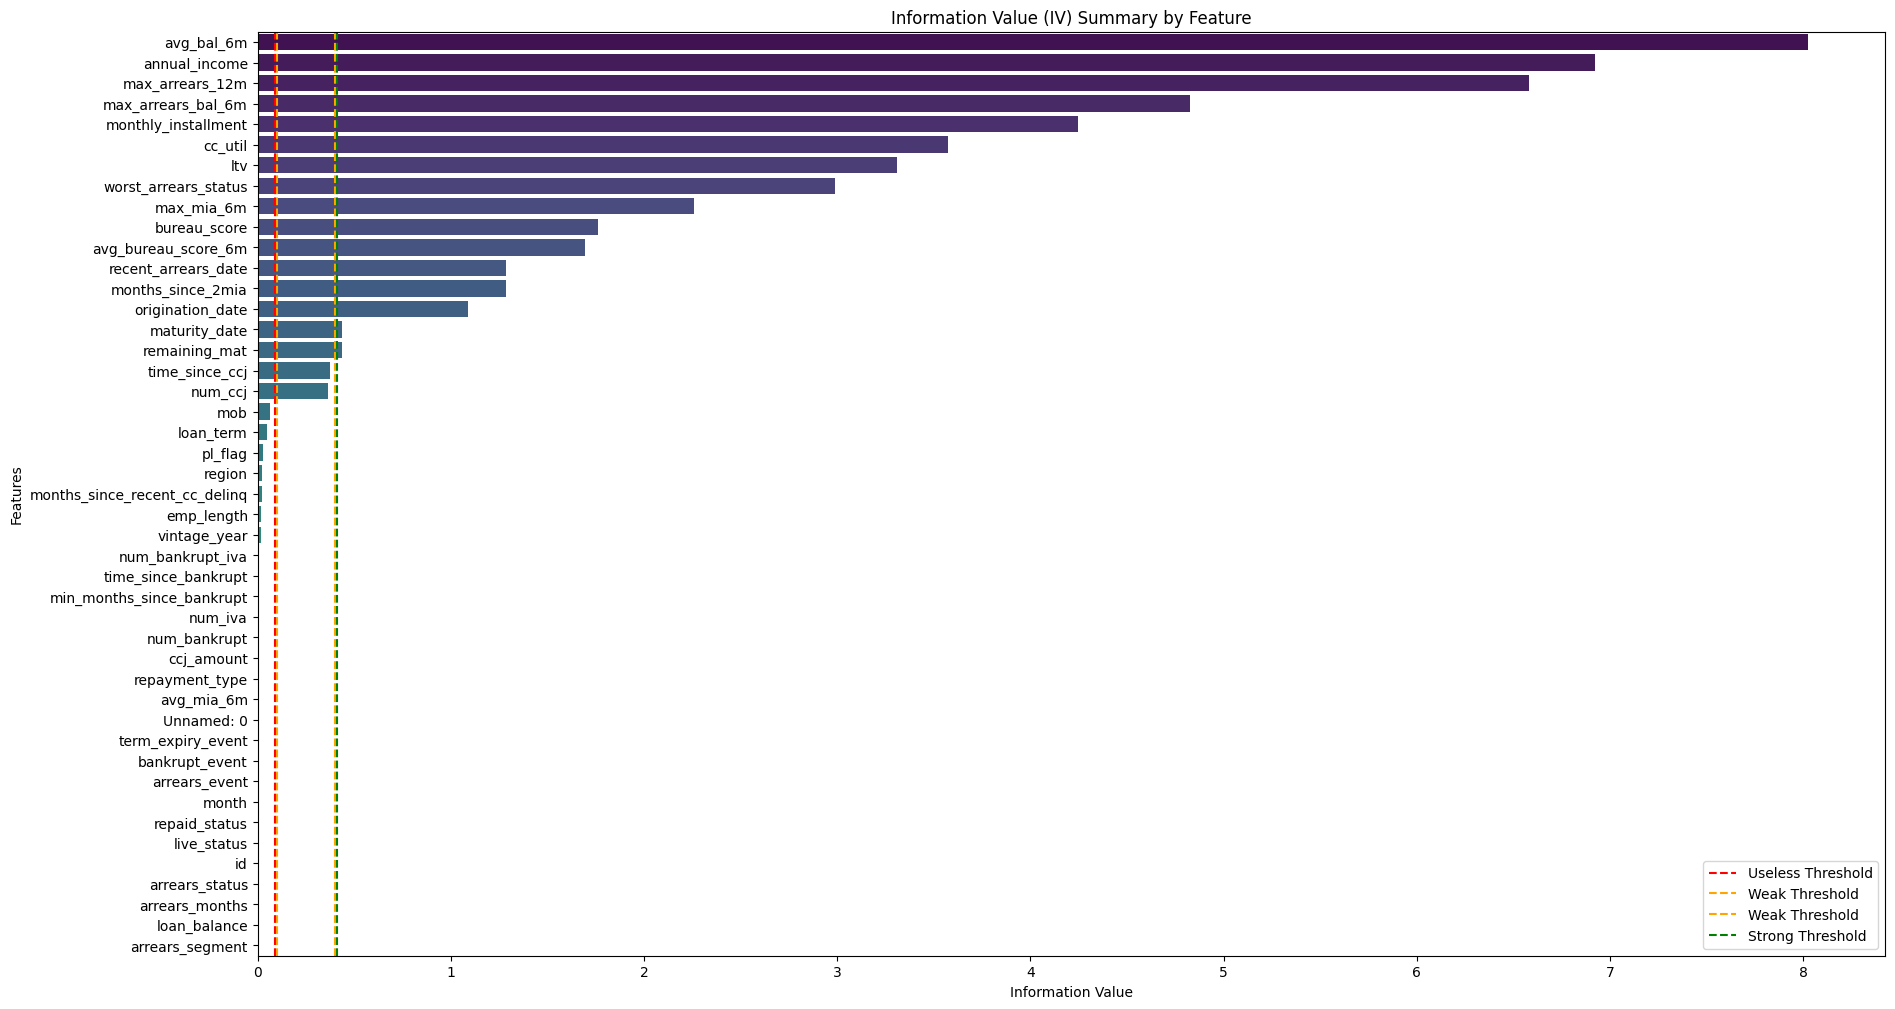

In [30]:
# plot IV summary to visualize the features of interest

import seaborn as sns

# sort iv summary by iv values
clean_summary = iv_summary.sort_values(by='iv', ascending=False)

# Plotting the IV Summary
plt.figure(figsize=(21, 12))
# hue is used in updated version of .barplot() - takes on y assignment
sns.barplot(x='iv', y='name', hue='name', data=clean_summary, palette='viridis')

# Adding visual cues for interpretation
plt.axvline(x=0.09, color='red', linestyle='--', label='Useless Threshold')
plt.axvline(x = 0.1, color='orange', linestyle='--', label='Weak Threshold')
plt.axvline(x = 0.4, color='orange', linestyle='--', label='Weak Threshold')
plt.axvline(x=0.41, color='green', linestyle='--', label='Strong Threshold')

plt.title('Information Value (IV) Summary by Feature')
plt.xlabel('Information Value')
plt.ylabel('Features')
plt.legend()
plt.show()

In [31]:
from optbinning import OptimalBinning

# features.to_numpy() needs to be undone - 'a' (features) need to be in df to use in .fit() of optimalBinning
df_a = pd.DataFrame(a)

# Dictionary to store the binning objects for each column
fitted_binners = {}

for col in df_a.columns:
    # Initialize a new binning instance for each feature
    
    # Optimal binning needs to know what data type the column name is in - condition below makes loop more efficient
    col_dtype = "categorical" if df_a[col].dtype == "object" else "numerical"

    # for 'name' in OptimalBinning, we need the column names to be of string type in order to be read --> str(col)
    optb = OptimalBinning(name=str(col), dtype=col_dtype, solver="cp")
    
    # Fit using the single column
    optb.fit(df_a[col], b)
    
    # Save the fitted model
    fitted_binners[col] = optb
    
    # Example: Print the table for the current column
    print(f"--- Binning Table for {col} ---")
    print(optb.binning_table.build())

--- Binning Table for 0 ---
                                                      Bin  Count  Count (%)  \
0       [1951, 1980, 2011, 2043, 2034, 2068, 2093, 210...  18134        1.0   
1                                                 Special      0        0.0   
2                                                 Missing      0        0.0   
Totals                                                     18134        1.0   

        Non-event  Event  Event rate  WoE   IV   JS  
0            1336  16798    0.926326  0.0  0.0  0.0  
1               0      0    0.000000  0.0  0.0  0.0  
2               0      0    0.000000  0.0  0.0  0.0  
Totals       1336  16798    0.926326       0.0  0.0  
--- Binning Table for 1 ---
                                                      Bin  Count  Count (%)  \
0       [1707561, 1718274, 1717840, 1716536, 1727468, ...  18134        1.0   
1                                                 Special      0        0.0   
2                                        

C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' wa

--- Binning Table for 2 ---
                                   Bin  Count  Count (%)  Non-event  Event  \
0                         [2012, 2005]   4081   0.225047        365   3716   
1                         [2013, 2004]   1718   0.094739        129   1589   
2                               [2006]   7379   0.406915        515   6864   
3                               [2007]   3188   0.175802        218   2970   
4       [2003, 2002, 2001, 2014, 2015]   1768   0.097496        109   1659   
5                              Special      0   0.000000          0      0   
6                              Missing      0   0.000000          0      0   
Totals                                  18134   1.000000       1336  16798   

        Event rate       WoE        IV        JS  
0         0.910561  0.211074  0.010973  0.001369  
1         0.924913  0.020532  0.000040  0.000005  
2         0.930207 -0.058299  0.001349  0.000169  
3         0.931619 -0.080242  0.001094  0.000137  
4         0.93

C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' wa

--- Binning Table for 4 ---
                                                      Bin  Count  Count (%)  \
0       [28205.56, 350988.56, 345647.07, 363278.35, 36...  18134        1.0   
1                                                 Special      0        0.0   
2                                                 Missing      0        0.0   
Totals                                                     18134        1.0   

        Non-event  Event  Event rate  WoE   IV   JS  
0            1336  16798    0.926326  0.0  0.0  0.0  
1               0      0    0.000000  0.0  0.0  0.0  
2               0      0    0.000000  0.0  0.0  0.0  
Totals       1336  16798    0.926326       0.0  0.0  
--- Binning Table for 5 ---
                                                      Bin  Count  Count (%)  \
0       [57.0, 62.0, 64.0, 77.0, 33.0, 103.0, 99.0, -6...    914   0.050403   
1       [181.0, 127.0, 104.0, 121.0, 139.0, 253.0, 207...   1245   0.068656   
2       [235.0, 305.0, 364.0, 246.0, 308.

...

C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' wa

--- Binning Table for 40 ---
                                                      Bin  Count  Count (%)  \
0       [-70.0, 88.0, 112.0, 52.0, 38.0, 124.0, 96.0, ...    923   0.050899   
1       [248.0, 162.0, 178.0, 234.0, 292.0, 194.0, 262...   1327   0.073177   
2       [256.0, 252.0, 150.0, 104.0, 118.0, 286.0, 272...    967   0.053325   
3       [336.0, 276.0, 310.0, 164.0, 174.0, 306.0, 326...    974   0.053711   
4       [340.0, 282.0, 266.0, 312.0, 160.0, 284.0, 342...   1746   0.096283   
5       [374.0, 300.0, 354.0, 400.0, 352.0, 450.0, 280...   1576   0.086909   
6       [380.0, 404.0, 414.0, 338.0, 368.0, 460.0, 370...   1129   0.062259   
7       [350.0, 382.0, 430.0, 466.0, 394.0, 384.0, 424...    941   0.051891   
8       [422.0, 376.0, 452.0, 548.0, 440.0, 356.0, 316...    964   0.053160   
9       [410.0, 556.0, 418.0, 398.0, 436.0, 480.0, 478...   1007   0.055531   
10      [462.0, 456.0, 432.0, 412.0, 458.0, 476.0, 416...   1690   0.093195   
11      [538.0, 536.0, 

C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' wa

--- Binning Table for 42 ---
                                                      Bin  Count  Count (%)  \
0       [39912, 21609, 21818, 106892, 105580, 104865, ...   1539   0.084868   
1       [47984, 53453, 52699, 41209, 54701, 55133, 564...  16595   0.915132   
2                                                 Special      0   0.000000   
3                                                 Missing      0   0.000000   
Totals                                                     18134   1.000000   

        Non-event  Event  Event rate       WoE        IV        JS  
0            1282    257    0.166992   4.13868  3.908079  0.298498  
1              54  16541    0.996746 -3.193034  3.015122  0.270131  
2               0      0    0.000000       0.0  0.000000  0.000000  
3               0      0    0.000000       0.0  0.000000  0.000000  
Totals       1336  16798    0.926326            6.923201  0.568628  
--- Binning Table for 43 ---
             Bin  Count  Count (%)  Non-event  Event 

C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\micha\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\deprecation.py:132: FutureWarning: 'force_all_finite' wa

In [32]:
from category_encoders import WOEEncoder

# Leave cols empty to auto-detect categorical columns - leaving argument empty defaults to using all columns. otherwise, specify the columns to be changed by .fit_transform()
enc = WOEEncoder()

# Fits and transforms all non-numeric columns - using X and y definitions from above
# X = info.drop('Default', axis=1)

# assign default data to y variable
# y = info['Default']

# transforms to WOE for features
df_transformed = enc.fit_transform(a, b)

In [33]:
# 'df' contains only your WOE-transformed variables
correlation_matrix = df_transformed.corr(method='spearman')

print(correlation_matrix)

    0   1         2         3         4         5         6         7   \
0  NaN NaN       NaN       NaN       NaN       NaN       NaN       NaN   
1  NaN NaN       NaN       NaN       NaN       NaN       NaN       NaN   
2  NaN NaN  1.000000  0.002547  0.006111  0.033088  0.009666  0.011286   
3  NaN NaN  0.002547  1.000000  0.032497  0.058633  0.001191  0.001292   
4  NaN NaN  0.006111  0.032497  1.000000  0.023748 -0.006723 -0.006574   
5  NaN NaN  0.033088  0.058633  0.023748  1.000000  0.129710  0.120215   
6  NaN NaN  0.009666  0.001191 -0.006723  0.129710  1.000000  0.934942   
7  NaN NaN  0.011286  0.001292 -0.006574  0.120215  0.934942  1.000000   
8  NaN NaN  0.018464  0.035688  0.014437  0.294270  0.230782  0.201487   
9  NaN NaN  0.017819  0.036712  0.014267  0.284798  0.219699  0.215466   
10 NaN NaN  0.023189  0.039724  0.013845  0.252326 -0.177249 -0.175478   
11 NaN NaN  0.016441  0.002727 -0.014128  0.017265  0.603820  0.576622   
12 NaN NaN  0.006355 -0.004418 -0.0065

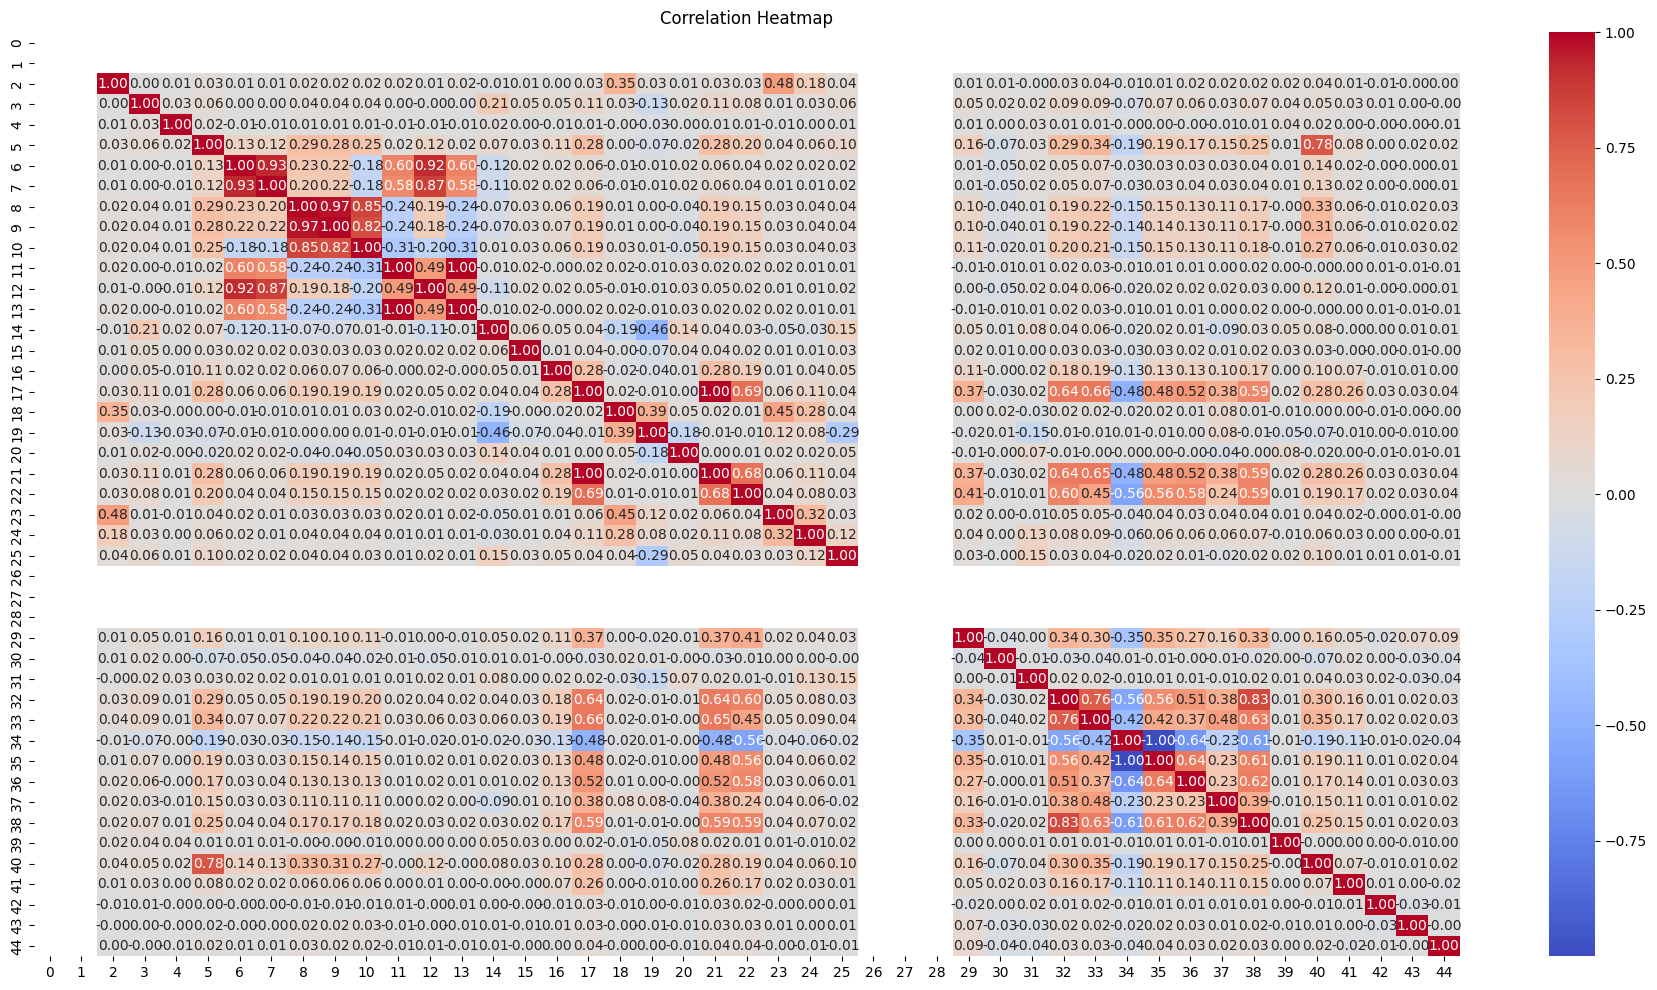

In [34]:
# heat map visualization of Spearman correlation
plt.figure(figsize=(23, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

#Before feeding these variables into a Logistic Regression model, calculating the Spearman Rank Correlation identifies multicollinearity
#:High Correlation (e.g., (>0.70)): Indicates that two WOE features provide identical information. To maintain stable model coefficients, you should drop one of them.
#Non-linear but Monotonic: Because Spearman measures ranked values, it captures non-linear predictive relationships that standard Pearson correlation might miss

In [55]:

# Perform Lasso regression to determine the relevant features to keep
from sklearn.linear_model import Lasso

# Initialize and fit the model
train_dataset = pd.DataFrame(X_train_encoded).copy()
train_dataset['target'] = y_train

# Drop rows with NaN
train_dataset_clean = train_dataset.dropna()

# Split them back apart
X_train_encoded = train_dataset_clean.drop(columns=['target'])
y_train = train_dataset_clean['target']


X_train_encoded = pd.get_dummies(X_train, columns=['region'], drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=['region'], drop_first=True)

# 2. Align train and test columns so they match exactly
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded, join='left', axis=1, fill_value=0
)

X_train_encoded = X_train_encoded.drop(columns=['origination_date', 'maturity_date', 'recent_arrears_date','repayment_type'], errors='ignore')
X_test_encoded = X_test_encoded.drop(columns=['origination_date', 'maturity_date', 'recent_arrears_date','repayment_type'], errors='ignore')

# 3. Ensure all columns are explicitly float or int type
X_train_encoded = X_train_encoded.astype(float)
X_test_encoded = X_test_encoded.astype(float)

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV

# 1. Create a pipeline with SimpleImputer and LassoCV
lasso_cv_pipeline = make_pipeline(
    SimpleImputer(strategy='median'), 
    LassoCV(cv=5, random_state=42)
)

# 2. Align training data indices
common_indices = X_train_encoded.index.intersection(y_train.index)
X_train_encoded = X_train_encoded.loc[common_indices]
y_train = y_train.loc[common_indices]

# 3. Fit the pipeline 
lasso_cv_pipeline.fit(X_train_encoded, y_train)

# 4. Extract the trained LassoCV step
lasso_cv_model = lasso_cv_pipeline.named_steps['lassocv']

# 5. Print the optimal alpha and intercept
print(f"Optimal Alpha: {lasso_cv_model.alpha_}")
print(f"Intercept: {lasso_cv_model.intercept_}\n")

# 6. Create a DataFrame matching every feature to its coefficient
coef_df = pd.DataFrame({
    'Feature': X_train_encoded.columns,
    'Coefficient': lasso_cv_model.coef_
})

# 7. Sort by coefficient value (highest positive impact to lowest negative impact)
sorted_features = coef_df.sort_values(by='Coefficient', ascending=False)

# 8. Print every single feature and its coefficient
print("All Features and Coefficients:")
pd.set_option('display.max_rows', None)  # Ensures pandas doesn't truncate the list
print(sorted_features.to_string(index=False))

# 9. Reset pandas option back to default
pd.reset_option('display.max_rows')

# 10. Make predictions
predictions = lasso_cv_pipeline.predict(X_test_encoded)

Optimal Alpha: 3235.6378083871664
Intercept: 0.18102479624176648

All Features and Coefficients:
                      Feature   Coefficient
                           id  9.235213e-09
                   Unnamed: 0 -0.000000e+00
                 vintage_year  0.000000e+00
          monthly_installment -0.000000e+00
                 loan_balance -0.000000e+00
                 bureau_score  0.000000e+00
             num_bankrupt_iva -0.000000e+00
          time_since_bankrupt -0.000000e+00
                      num_ccj -0.000000e+00
               time_since_ccj -0.000000e+00
                   ccj_amount  0.000000e+00
                 num_bankrupt -0.000000e+00
                      num_iva -0.000000e+00
    min_months_since_bankrupt -0.000000e+00
                      pl_flag -0.000000e+00
                          ltv -0.000000e+00
               arrears_months -0.000000e+00
               arrears_status -0.000000e+00
              arrears_segment -0.000000e+00
                       

In [56]:
feature_names = X_train_encoded.columns

# 2. Access the lasso step (make_pipeline uses lowercase class names)
lasso_model = lasso_pipeline.named_steps['lasso']
coefficients = lasso_model.coef_

# 3. Create a clean, sorted DataFrame
coeff_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
}).sort_values(by='Abs_Coefficient', ascending=False)

# 4. View the results
print("\n--- Top Features Selected by Lasso ---")
print(coeff_df)


--- Top Features Selected by Lasso ---
                          Feature   Coefficient  Abs_Coefficient
32             max_arrears_bal_6m -1.774429e-04     1.774429e-04
3             monthly_installment  9.731622e-05     9.731622e-05
5                    bureau_score  7.106128e-05     7.106128e-05
20                  remaining_mat -4.224509e-05     4.224509e-05
34                     avg_bal_6m  2.976111e-05     2.976111e-05
4                    loan_balance -2.913180e-05     2.913180e-05
0                      Unnamed: 0 -3.317728e-06     3.317728e-06
37                  annual_income  1.026109e-06     1.026109e-06
10                     ccj_amount  3.030345e-07     3.030345e-07
1                              id  6.347893e-09     6.347893e-09
9                  time_since_ccj -0.000000e+00     0.000000e+00
11                   num_bankrupt  0.000000e+00     0.000000e+00
12                        num_iva -0.000000e+00     0.000000e+00
13      min_months_since_bankrupt -0.000000e+00   